In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Cargar dataset procesado
ruta_base = os.path.abspath(os.path.join(os.getcwd(), ".."))
path_csv = os.path.join(ruta_base, "data", "processed", "poblacion_atendida_limpia.csv")

df = pd.read_csv(path_csv)
df.head()

C:\Users\Usuario 1\AppData\Local\Temp\ipykernel_10040\1266103317.py:15: DtypeWarning: Columns (0: codigo_aseguradora) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(path_csv)


,año,periodo_reporte,fecha_atencion,servicio,sexo,codigo_aseguradora,aseguradora,poblacion,Departamento,edad,rango_edad,regimen
0,2022,1,2022-01-02T00:00:00.000-05:00,AMBULATORIO,M,20002686.0,ALIANZA MEDELLIN ANTIOQUIA EPS SUBSIDIADO ISS ...,Veinte de Julio SAN JAVIER,ANTIOQUIA,2,1 - 4 aNos,REgimen Subsidiado
1,2022,1,2022-01-02T00:00:00.000-05:00,AMBULATORIO,M,20000362.0,"AXA COLPATRIA SEGUROS SA, SOAT",Barrio Cristobal LA AMERICA,ANTIOQUIA,35,15 - 44 aNos,Otros
2,2022,1,2022-01-02T00:00:00.000-05:00,AMBULATORIO,M,20000368.0,SEGUROS LA PREVISORA,Playon de Los Comuneros SANTA CRUZ,ANTIOQUIA,24,15 - 44 aNos,Otros
3,2022,1,2022-01-02T00:00:00.000-05:00,AMBULATORIO,M,20000366.0,SEGUROS DEL ESTADO,Aures No2 ROBLEDO,ANTIOQUIA,23,15 - 44 aNos,Otros
4,2022,1,2022-01-02T00:00:00.000-05:00,HOSPITALIZADO,M,20000368.0,SEGUROS LA PREVISORA,MEDELLIN,ANTIOQUIA,32,15 - 44 aNos,Otros


In [ ]:
variables_modelo = ['edad', 'sexo', 'rango_edad', 'regimen', 'Departamento', 'servicio']
df_modelo = df[variables_modelo].dropna().copy()

le = LabelEncoder()

df_modelo['sexo_cod'] = le.fit_transform(df_modelo['sexo'])
df_modelo['rango_edad_cod'] = le.fit_transform(df_modelo['rango_edad'])
df_modelo['regimen_cod'] = le.fit_transform(df_modelo['regimen'])
df_modelo['depto_cod'] = le.fit_transform(df_modelo['Departamento'])


df_modelo['servicio_cod'] = le.fit_transform(df_modelo['servicio'])


X = df_modelo[['edad', 'sexo_cod', 'rango_edad_cod', 'regimen_cod', 'depto_cod']]
y = df_modelo['servicio_cod']

print("Variables transformadas correctamente:")
X.head()

Variables transformadas correctamente:


,edad,sexo_cod,rango_edad_cod,regimen_cod,depto_cod
0,2,1,1,20,0
1,35,1,4,12,0
2,24,1,4,12,0
3,23,1,4,12,0
4,32,1,4,12,0


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)


modelo = RandomForestClassifier(random_state=42)
modelo.fit(X_train, y_train)

print("¡Modelo entrenado con éxito!")

¡Modelo entrenado con éxito!


Exactitud (Accuracy): 0.745057232049948

Reporte de Clasificación:
              precision    recall  f1-score   support

           0       0.75      0.98      0.85     27255
           1       0.48      0.05      0.10      9263

    accuracy                           0.75     36518
   macro avg       0.62      0.52      0.47     36518
weighted avg       0.68      0.75      0.66     36518



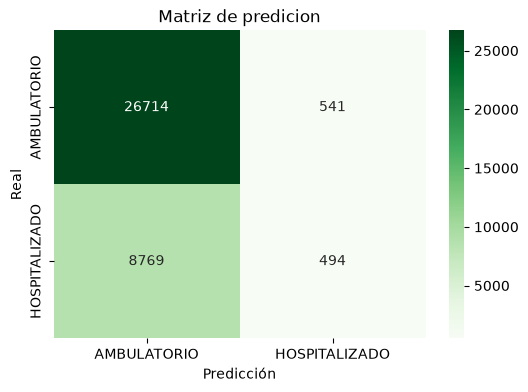

In [5]:
y_pred = modelo.predict(X_test)


print("Exactitud (Accuracy):", accuracy_score(y_test, y_pred))
print("\nReporte de Clasificación:")
print(classification_report(y_test, y_pred))


cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', xticklabels=le.classes_, yticklabels=le.classes_)
plt.title('Matriz de predicion')
plt.xlabel('Predicción')

plt.ylabel('Real')
plt.show()